# Мини-проект к защите: модификация задачи оптимального управления

Мини-проект сдаётся вместе с домашней работой из `sem5`.

В `sem5` использовался маятник
$$
\dot\theta=\omega,\qquad
\dot\omega=-\sin\theta+u.
$$

В мини-проекте модель меняется. Добавим вязкое трение:
$$
\dot\theta=\omega,
$$
$$
\dot\omega=-\sin\theta-\gamma\omega+u.
$$

Кроме терминального штрафа добавим штраф на состояние вдоль всей траектории:
$$
J=
20(\theta(T)-\pi)^2+
5\omega(T)^2+
\int_0^T
\left[
q_\theta(\theta-\pi)^2+
q_\omega\omega^2+
\lambda u^2
\right]dt.
$$

Основные параметры:
$$
T=5,\qquad N=80,\qquad |u|\le2,
$$
$$
\gamma=0.15,\qquad
q_\theta=0.1,\qquad
q_\omega=0.05,\qquad
\lambda=0.05.
$$

Задача мини-проекта:

1. вывести дискретную сопряжённую систему для новой постановки;
2. реализовать новый градиент;
3. проверить градиент численно;
4. решить задачу своим методом проекции градиента с backtracking;
5. провести один численный эксперимент по своему варианту;
6. объяснить результат на защите.

## 0. Импорт и параметры

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize

T = 5.0
N = 80
u_max = 2.0

x0 = np.array([0.0, 0.0])
x_target = np.array([np.pi, 0.0])

w_theta = 20.0
w_omega = 5.0

gamma = 0.15
q_theta = 0.10
q_omega = 0.05
lam = 0.05

# 1. Новая дискретная модель

Используем явный Euler:
$$
\theta_{k+1}=\theta_k+h\omega_k,
$$
$$
\omega_{k+1}
=
\omega_k+
h(-\sin\theta_k-\gamma\omega_k+u_k).
$$

Напишите функцию
```python
simulate_pendulum(u, gamma)
```

Параметр `gamma` должен передаваться аргументом функции.

In [22]:
def simulate_pendulum(u, gamma):
    n = len(u)
    h = T / n

    x = np.zeros((n + 1, 2))
    x[0] = x0

    for k in range(n):
        theta, omega = x[k]

        x[k + 1, 0] = theta + h * omega
        x[k + 1, 1] = omega + h * (
            -np.sin(theta) - gamma * omega + u[k]
        )

    return x

Функционал после дискретизации:
$$
J=
\Phi(x_N)+
\sum_{k=0}^{N-1}L_k(x_k,u_k),
$$
где
$$
\Phi(x_N)
=
20(\theta_N-\pi)^2+
5\omega_N^2,
$$
$$
L_k
=
h\left[
q_\theta(\theta_k-\pi)^2+
q_\omega\omega_k^2+
\lambda u_k^2
\right].
$$

Напишите
```python
objective_pendulum(u, gamma, q_theta, q_omega, lam)
```

In [23]:
def objective_pendulum(
    u,
    gamma,
    q_theta,
    q_omega,
    lam,
):
    x = simulate_pendulum(u, gamma)
    h = T / len(u)

    theta = x[:, 0]
    omega = x[:, 1]

    terminal_cost = 20 * (theta[-1] - np.pi)**2 + 5 * omega[-1]**2

    running_cost = h * np.sum(
        q_theta * (theta[:-1] - np.pi)**2
        + q_omega * omega[:-1]**2
        + lam * u**2
    )

    return terminal_cost + running_cost

# 2. Сопряжённая система

Для дискретной задачи
$$
x_{k+1}=F_k(x_k,u_k),
$$
$$
J=\Phi(x_N)+\sum_{k=0}^{N-1}L_k(x_k,u_k)
$$
используем формулы
$$
p_N=\nabla\Phi(x_N),
$$
$$
p_k=
F_{x,k}^{\mathsf T}p_{k+1}
+
\nabla_xL_k,
$$
$$
\nabla_{u_k}J
=
F_{u,k}^{\mathsf T}p_{k+1}
+
\nabla_uL_k.
$$

## Задание

В Markdown-ячейке ниже выпишите для нашей задачи:

1. матрицу $F_x$;
2. вектор $F_u$;
3. $\nabla_xL_k$;
4. $\nabla_uL_k$;
5. терминальное условие $p_N$;
6. формулу для $p_k$;
7. формулу для компоненты градиента $g_k$.

Это часть работы. На защите нужно будет объяснить хотя бы одну из этих формул.

### Ваш вывод

1. матрица производных дискретной динамики по состоянию

   $$
   F_{x,k} =
   \begin{pmatrix}
   1 & h \\
   -h\cos\theta_k & 1-h\gamma
   \end{pmatrix}
   $$

2. вектор производных дискретной динамики по управлению

   $$
   F_{u,k} =
   \begin{pmatrix}
   0 \\
   h
   \end{pmatrix}
   $$

3. градиент текущего штрафа по состоянию

   $$
   \nabla_x L_k =
   \begin{pmatrix}
   2hq_\theta(\theta_k-\pi) \\
   2hq_\omega\omega_k
   \end{pmatrix}
   $$

4. производная текущего штрафа по управлению

   $$
   \nabla_u L_k = 2h\lambda u_k
   $$

5. терминальное условие для сопряжённых переменных

   $$
   p_N =
   \begin{pmatrix}
   40(\theta_N-\pi) \\
   10\omega_N
   \end{pmatrix}
   $$

6. рекуррентная формула сопряжённой системы

   $$
   p_k = F_{x,k}^{\mathsf{T}}p_{k+1}+\nabla_x L_k
   $$

   в покомпонентном виде

   $$
   \begin{aligned}
   p_{\theta,k} &=
   p_{\theta,k+1}
   -h\cos\theta_k\,p_{\omega,k+1}
   +2hq_\theta(\theta_k-\pi),\\
   p_{\omega,k} &=
   hp_{\theta,k+1}
   +(1-h\gamma)p_{\omega,k+1}
   +2hq_\omega\omega_k
   \end{aligned}
   $$

7. компонента градиента функционала по управлению

   $$
   g_k = hp_{\omega,k+1}+2h\lambda u_k
   $$

После вывода реализуйте новый сопряжённый градиент.

Функция должна принимать те же параметры задачи, что и `objective_pendulum`.

In [24]:
def adjoint_gradient_pendulum(
    u,
    gamma,
    q_theta,
    q_omega,
    lam,
):
    n = len(u)
    h = T / n

    x = simulate_pendulum(u, gamma)

    p = np.zeros((n + 1, 2))
    p[n, 0] = 40 * (x[n, 0] - np.pi)
    p[n, 1] = 10 * x[n, 1]

    g = np.zeros(n)

    for k in range(n - 1, -1, -1):
        theta, omega = x[k]

        g[k] = h * p[k + 1, 1] + 2 * h * lam * u[k]

        p[k, 0] = (
            p[k + 1, 0]
            - h * np.cos(theta) * p[k + 1, 1]
            + 2 * h * q_theta * (theta - np.pi)
        )

        p[k, 1] = (
            h * p[k + 1, 0]
            + (1 - h * gamma) * p[k + 1, 1]
            + 2 * h * q_omega * omega
        )

    return g

# 3. Проверка градиента

До оптимизации проверьте реализацию через производную по направлению.

Возьмите случайные $u$ и $v$ и сравните
$$
\nabla J(u)^\mathsf{T}v
$$
с
$$
\frac{
J(u+\varepsilon v)-J(u-\varepsilon v)
}{
2\varepsilon
}.
$$

Используйте несколько значений
$$
\varepsilon=10^{-4},10^{-5},10^{-6},10^{-7}.
$$

Сделайте небольшую таблицу:

- $\varepsilon$;
- производная по сопряжённому градиенту;
- конечная разность;
- относительная ошибка.

Рабочая реализация должна давать малую ошибку хотя бы для части этих $\varepsilon$.

In [25]:
# Ваш gradient check
rng = np.random.default_rng(42)

u_test = 0.2 * rng.normal(size=N)
v = rng.normal(size=N)
v /= np.linalg.norm(v)

g_test = adjoint_gradient_pendulum(
    u_test, gamma, q_theta, q_omega, lam
)
directional_adjoint = g_test @ v

results = []

for eps in [1e-4, 1e-5, 1e-6, 1e-7]:
    directional_fd = (
        objective_pendulum(
            u_test + eps * v, gamma, q_theta, q_omega, lam
        )
        - objective_pendulum(
            u_test - eps * v, gamma, q_theta, q_omega, lam
        )
    ) / (2 * eps)

    relative_error = (
        abs(directional_adjoint - directional_fd)
        / max(1.0, abs(directional_adjoint))
    )

    results.append({
        "epsilon": eps,
        "adjoint": directional_adjoint,
        "finite difference": directional_fd,
        "relative error": relative_error,
    })

pd.DataFrame(results)

,epsilon,adjoint,finite difference,relative error
0,1.000000e-04,-3.031935,-3.031935,4.538449e-11
1,1.000000e-05,-3.031935,-3.031935,1.170279e-09
2,1.000000e-06,-3.031935,-3.031935,9.606983e-09
3,1.000000e-07,-3.031935,-3.031935,4.241639e-08


<span style="color:red">Вывод:</span>

1. производная по сопряжённому градиенту согласуется с численной производной для всех рассмотренных значений $\varepsilon$
2. относительная ошибка составляет от $4.54\cdot10^{-11}$ до $4.24\cdot10^{-8}$, что подтверждает корректность реализации градиента
3. при уменьшении $\varepsilon$ ошибка возрастает из-за погрешностей вычислений с плавающей точкой

# 4. Решение своим методом

Перенесите из `sem5` свою функцию `projected_gradient_backtracking`.

Адаптируйте её к новым функциям `objective_pendulum` и `adjoint_gradient_pendulum`.

Начальное управление:
$$
u^0=0.
$$

Сохраните:

- $J$ по итерациям;
- принятый шаг $\alpha$;
- найденное управление;
- число итераций.

Постройте:

1. историю $J$;
2. $u(t)$;
3. $\theta(t)$;
4. $\omega(t)$;
5. фазовую траекторию.

In [26]:
def projected_gradient_backtracking(
    u0,
    gamma,
    q_theta,
    q_omega,
    lam,
    alpha0=0.3,
    beta=0.5,
    c=1e-4,
    maxiter=1000,
    tol=1e-7,
):
    u = u0.copy()

    history = [
        objective_pendulum(u, gamma, q_theta, q_omega, lam)
    ]
    accepted_alpha = []

    for _ in range(maxiter):
        J_current = history[-1]
        grad = adjoint_gradient_pendulum(
            u, gamma, q_theta, q_omega, lam
        )

        alpha = alpha0

        while True:
            u_new = np.clip(
                u - alpha * grad,
                -u_max,
                u_max,
            )

            direction = u_new - u

            J_new = objective_pendulum(
                u_new, gamma, q_theta, q_omega, lam
            )

            if J_new <= J_current + c * grad @ direction:
                break

            alpha *= beta

        accepted_alpha.append(alpha)
        history.append(J_new)

        if np.linalg.norm(direction, ord=np.inf) < tol:
            u = u_new
            break

        u = u_new

    return (
        u,
        np.array(history),
        np.array(accepted_alpha),
    )

J = 2.0801887995941724
iterations = 1000
x(T) = [ 3.14481047 -0.02892468]
last alpha = 0.01875


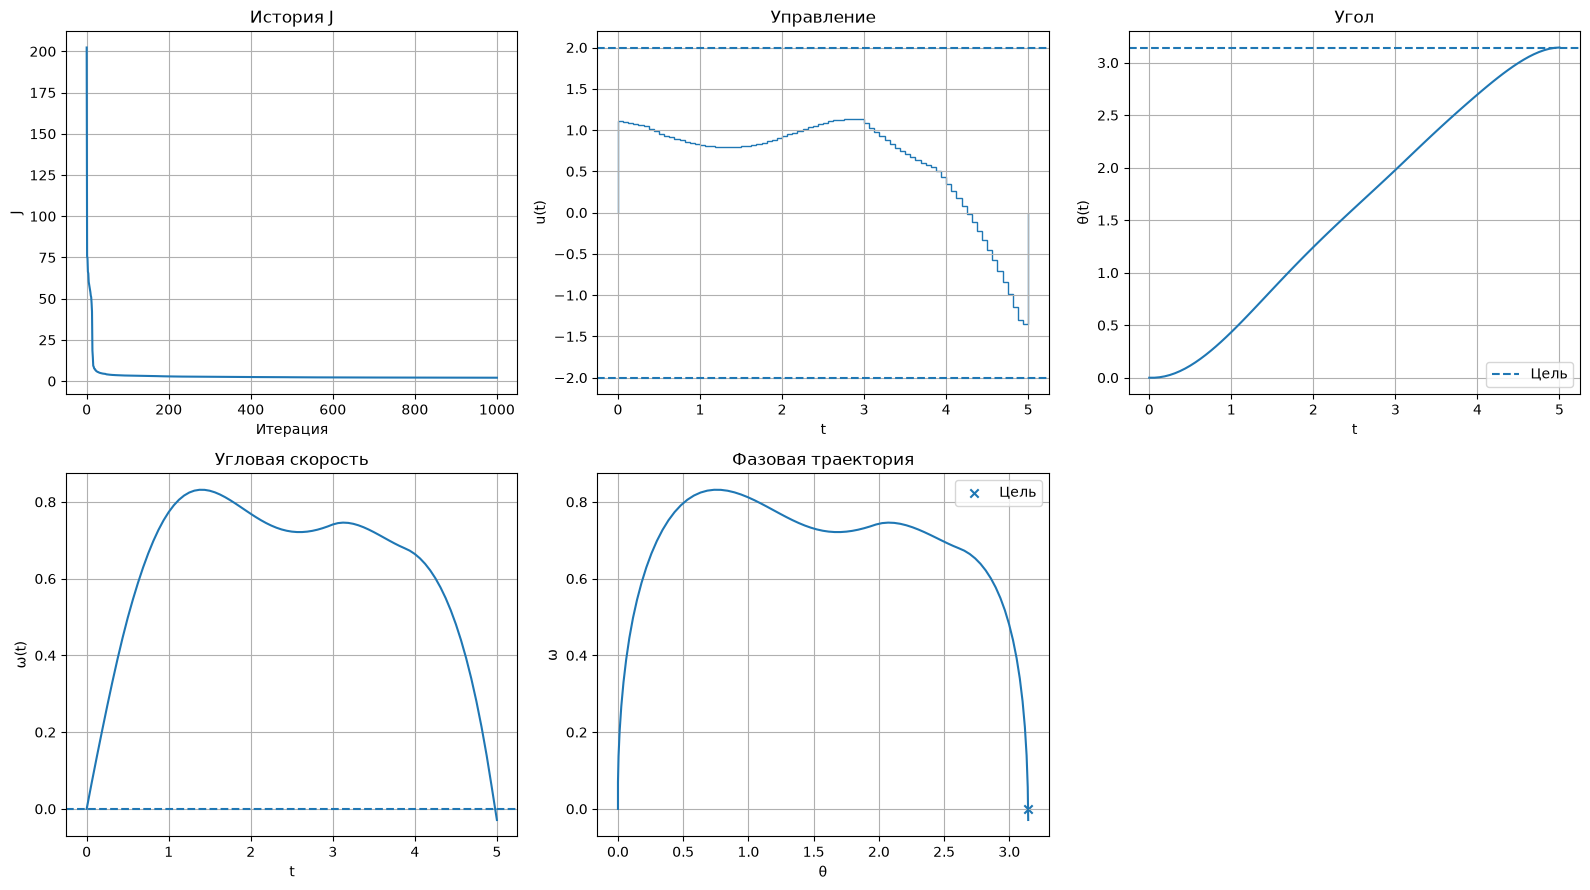

In [27]:
# Запуск метода и графики
u0 = np.zeros(N)

u_opt, J_history, alpha_history = projected_gradient_backtracking(
    u0, gamma, q_theta, q_omega, lam
)

n_iter = len(alpha_history)
x_opt = simulate_pendulum(u_opt, gamma)

t = np.linspace(0, T, N + 1)

print("J =", J_history[-1])
print("iterations =", n_iter)
print("x(T) =", x_opt[-1])
print("last alpha =", alpha_history[-1])

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
axs = axs.ravel()

axs[0].plot(J_history)
axs[0].set(title="История J", xlabel="Итерация", ylabel="J")

axs[1].stairs(u_opt, t)
axs[1].axhline(u_max, linestyle="--")
axs[1].axhline(-u_max, linestyle="--")
axs[1].set(title="Управление", xlabel="t", ylabel="u(t)")

axs[2].plot(t, x_opt[:, 0])
axs[2].axhline(np.pi, linestyle="--", label="Цель")
axs[2].set(title="Угол", xlabel="t", ylabel="θ(t)")
axs[2].legend()

axs[3].plot(t, x_opt[:, 1])
axs[3].axhline(0, linestyle="--")
axs[3].set(title="Угловая скорость", xlabel="t", ylabel="ω(t)")

axs[4].plot(x_opt[:, 0], x_opt[:, 1])
axs[4].scatter(np.pi, 0, marker="x", label="Цель")
axs[4].set(title="Фазовая траектория", xlabel="θ", ylabel="ω")
axs[4].legend()

for ax in axs[:5]:
    ax.grid()

fig.delaxes(axs[5])
plt.tight_layout()
plt.show()

<span style="color:red">Вывод:</span>

1. метод проекции градиента с backtracking уменьшил функционал до $J \approx 2.0802$ за 1000 итераций
2. конечное состояние маятника близко к целевому: $\theta(T) \approx 3.1448$, $\omega(T) \approx -0.0289$
3. управление удовлетворяет ограничению $|u(t)| \leq 2$, а значение функционала последовательно уменьшается
4. метод достиг максимального числа итераций, поэтому полная сходимость не подтверждена, однако полученное управление обеспечивает достаточно точное приближение к цели

# 5. Проверка через `L-BFGS-B`

Решите ту же задачу через `L-BFGS-B`, передав ваш новый сопряжённый градиент в `jac`.

Сравните с методом проекции:

- $J$;
- terminal error;
- control effort
$$
h\sum_k u_k^2;
$$
- число итераций;
- найденное управление.

`L-BFGS-B` здесь используется как численный ориентир.

,Метод,J,Terminal error,Control effort,Iterations
0,Projected Gradient,2.080189,0.029103,3.851350,1000
1,L-BFGS-B,1.526823,0.001356,4.172875,146


L-BFGS-B success: True
L-BFGS-B message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
L-BFGS-B x(T): [3.14119466e+00 1.29581184e-03]


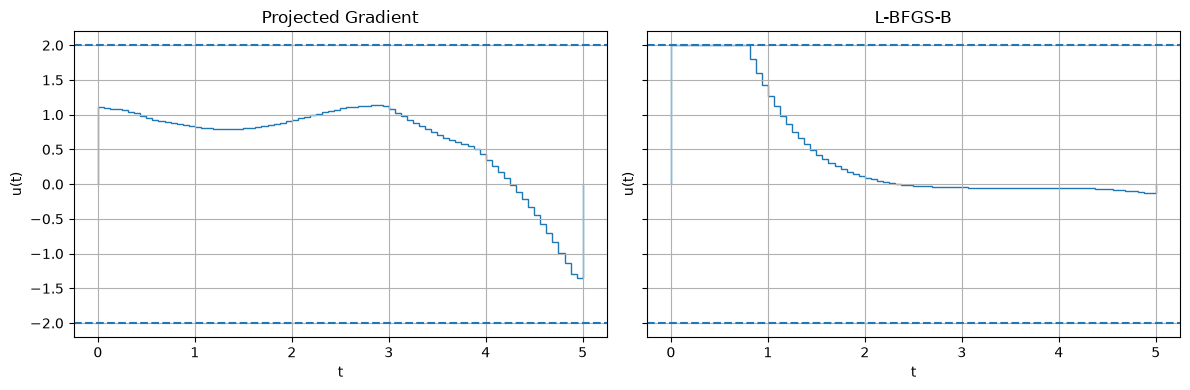

In [28]:
# Ваш код для L-BFGS-B и итоговой таблицы
res_lbfgsb = minimize(
    objective_pendulum,
    u0,
    args=(gamma, q_theta, q_omega, lam),
    jac=adjoint_gradient_pendulum,
    method="L-BFGS-B",
    bounds=[(-u_max, u_max)] * N,
    options={"maxiter": 1000},
)

u_lbfgsb = res_lbfgsb.x
x_lbfgsb = simulate_pendulum(u_lbfgsb, gamma)

h = T / N
target = np.array([np.pi, 0.0])

comparison = pd.DataFrame({
    "Метод": ["Projected Gradient", "L-BFGS-B"],
    "J": [J_history[-1], res_lbfgsb.fun],
    "Terminal error": [
        np.linalg.norm(x_opt[-1] - target),
        np.linalg.norm(x_lbfgsb[-1] - target),
    ],
    "Control effort": [
        h * np.sum(u_opt**2),
        h * np.sum(u_lbfgsb**2),
    ],
    "Iterations": [
        len(alpha_history),
        res_lbfgsb.nit,
    ],
})

display(comparison)

print("L-BFGS-B success:", res_lbfgsb.success)
print("L-BFGS-B message:", res_lbfgsb.message)
print("L-BFGS-B x(T):", x_lbfgsb[-1])

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axs[0].stairs(u_opt, t)
axs[0].set_title("Projected Gradient")

axs[1].stairs(u_lbfgsb, t)
axs[1].set_title("L-BFGS-B")

for ax in axs:
    ax.axhline(u_max, linestyle="--")
    ax.axhline(-u_max, linestyle="--")
    ax.set(xlabel="t", ylabel="u(t)")
    ax.set_ylim(-2.2, 2.2)
    ax.grid()

plt.tight_layout()
plt.show()

<span style="color:red">Ответ:</span>

1. метод L-BFGS-B достиг меньшего значения функционала $J \approx 1.5268$ против $J \approx 2.0802$ у метода проекции градиента
2. терминальная ошибка уменьшилась с $0.0291$ до $0.00136$, что свидетельствует о более точном достижении целевого состояния
3. затраты на управление у L-BFGS-B оказались несколько выше: $4.1729$ против $3.8514$
4. L-BFGS-B завершился за 146 итераций, тогда как метод проекции градиента достиг ограничения в 1000 итераций
5. оба метода соблюдают ограничения на управление, однако L-BFGS-B в данном эксперименте обеспечил лучшее значение функционала и меньшую терминальную ошибку

# 6. Индивидуальный эксперимент

Номер варианта определяется номером студента в списке группы:

- остаток 1 при делении на 3 — **вариант A**;
- остаток 2 — **вариант B**;
- остаток 0 — **вариант C**.

Перед расчётами напишите 1–2 предложения с прогнозом.

## Вариант A. Вязкое трение

Исследуйте
$$
\gamma=0,\quad0.1,\quad0.2,\quad0.3.
$$

Для каждого значения сохраните:

- $J$;
- terminal error;
- control effort;
- $\max|u|$.

Постройте управления на одном графике.

Объясните, как трение меняет оптимальную стратегию.

## Вариант B. Штраф за отклонение угла

Исследуйте
$$
q_\theta=0,\quad0.05,\quad0.2,\quad0.5.
$$

Сохраните те же показатели.

Объясните, как интегральный штраф за $(\theta-\pi)^2$ меняет траекторию и управление.

## Вариант C. Штраф за угловую скорость

Исследуйте
$$
q_\omega=0,\quad0.05,\quad0.2,\quad0.5.
$$

Сохраните те же показатели.

Объясните, как штраф за $\omega^2$ меняет движение и управление.

<span style="color:red">Прогноз:</span>

1. при увеличении коэффициента $q_\omega$ ожидается уменьшение суммарной квадратичной угловой скорости, поскольку движение с большими скоростями становится более затратным
2. при фиксированном времени движения это может привести к изменению оптимального управления и увеличению ошибки достижения конечного состояния


,q_omega,J,Terminal error,Control effort,Speed integral,Max |omega|,Iterations,Success,Max |u|
0,0.00,1.419555,0.027596,4.304211,3.047350,1.466265,74,True,2.0
1,0.05,1.526823,0.001356,4.172875,3.381232,1.577574,146,True,2.0
2,0.20,2.016049,0.003919,4.156867,2.945712,1.385437,89,True,2.0
3,0.50,2.774806,0.016429,3.765754,2.411134,1.110713,87,True,2.0


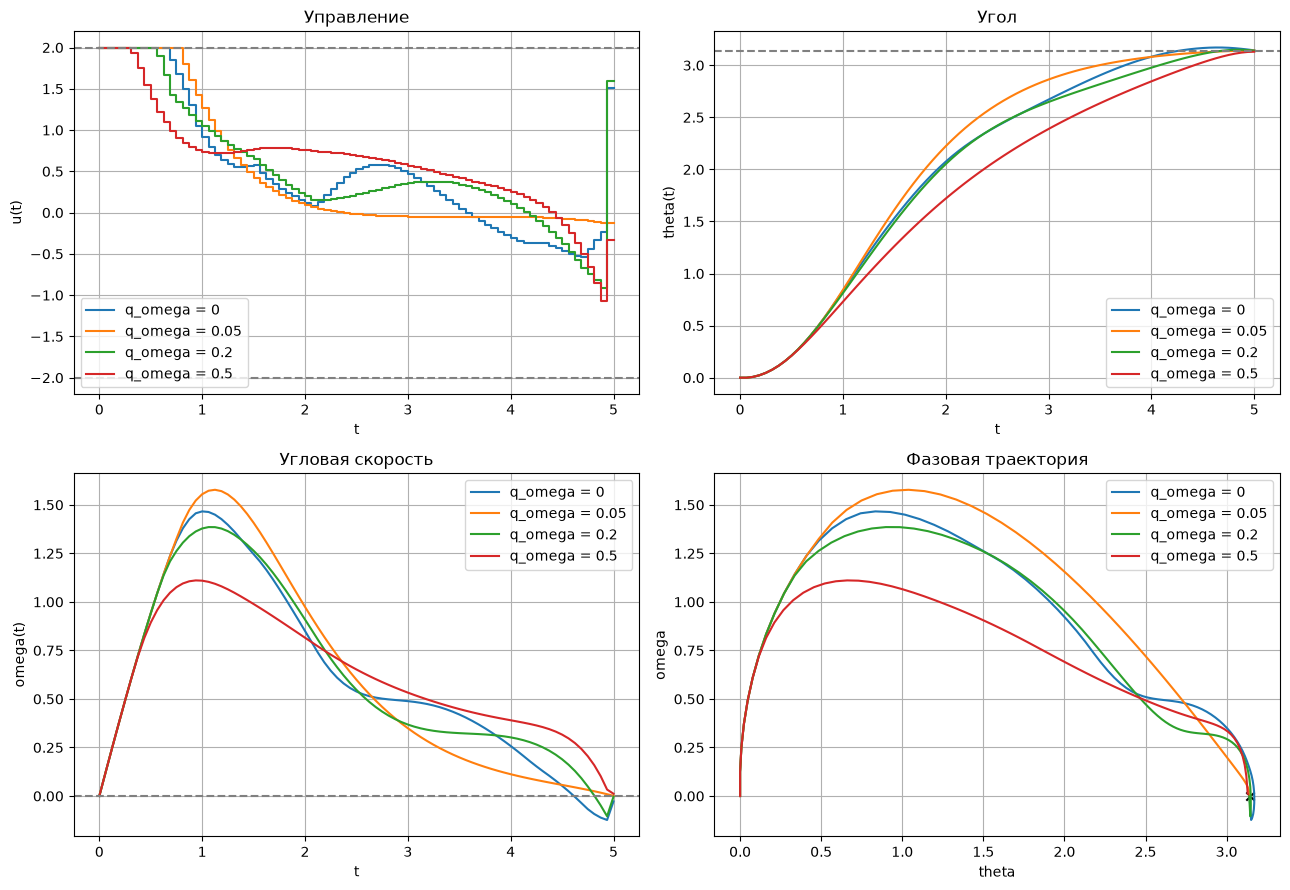

In [30]:
# Ваш индивидуальный эксперимент
q_omega_values = [0, 0.05, 0.2, 0.5]

results_c = []
solutions_c = {}

h = T / N
t = np.linspace(0, T, N + 1)
target = np.array([np.pi, 0.0])

for q_w in q_omega_values:
    res = minimize(
        objective_pendulum,
        u0,
        args=(gamma, q_theta, q_w, lam),
        jac=adjoint_gradient_pendulum,
        method="L-BFGS-B",
        bounds=[(-u_max, u_max)] * N,
        options={"maxiter": 1000},
    )

    u = res.x
    x = simulate_pendulum(u, gamma)

    solutions_c[q_w] = (u, x)

    results_c.append({
        "q_omega": q_w,
        "J": res.fun,
        "Terminal error": np.linalg.norm(x[-1] - target),
        "Control effort": h * np.sum(u**2),
        "Speed integral": h * np.sum(x[:-1, 1]**2),
        "Max |omega|": np.max(np.abs(x[:, 1])),
        "Iterations": res.nit,
        "Success": res.success,
        "Max |u|": np.max(np.abs(u)),
    })

df_c = pd.DataFrame(results_c)
display(df_c.round(6))

fig, axs = plt.subplots(2, 2, figsize=(13, 9))

for q_w, (u, x) in solutions_c.items():
    label = f"q_omega = {q_w}"

    axs[0, 0].step(
        t, np.r_[u, u[-1]], where="post", label=label
    )
    axs[0, 1].plot(t, x[:, 0], label=label)
    axs[1, 0].plot(t, x[:, 1], label=label)
    axs[1, 1].plot(x[:, 0], x[:, 1], label=label)

axs[0, 0].axhline(u_max, linestyle="--", color="gray")
axs[0, 0].axhline(-u_max, linestyle="--", color="gray")
axs[0, 0].set(title="Управление", xlabel="t", ylabel="u(t)")

axs[0, 1].axhline(np.pi, linestyle="--", color="gray")
axs[0, 1].set(title="Угол", xlabel="t", ylabel="theta(t)")

axs[1, 0].axhline(0, linestyle="--", color="gray")
axs[1, 0].set(title="Угловая скорость", xlabel="t", ylabel="omega(t)")

axs[1, 1].scatter(np.pi, 0, marker="x", color="black")
axs[1, 1].set(
    title="Фазовая траектория",
    xlabel="theta",
    ylabel="omega",
)

for ax in axs.flat:
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

<span style="color:red">Вывод:</span>

1. при увеличении $q_\omega$ от $0.05$ до $0.5$ интеграл квадрата угловой скорости уменьшается с $3.3812$ до $2.4111$, а максимальная скорость — с $1.5776$ до $1.1107$, что подтверждает основной прогноз
2. при $q_\omega=0$ интеграл квадрата скорости оказался меньше, чем при $q_\omega=0.05$, что может быть связано с нахождением разных локальных минимумов невыпуклой задачи
3. увеличение штрафа за скорость изменяет форму управления и траекторию движения, при этом для $q_\omega=0.5$ терминальная ошибка выше, чем для базового значения $q_\omega=0.05$
4. значение функционала возрастает с $1.4196$ до $2.7748$, однако сравнивать качество решений только по $J$ нельзя, поскольку при изменении $q_\omega$ изменяется сам функционал
5. таким образом, увеличение штрафа за угловую скорость в целом способствует более плавному движению с меньшими скоростями, но может ухудшать точность достижения целевого состояния за фиксированное время

# Итог

В конце напишите 6–10 предложений:

- прошёл ли gradient check;
- чем новая сопряжённая система отличается от задачи из `sem5`;
- насколько близки решения projected gradient и `L-BFGS-B`;
- что показал ваш индивидуальный эксперимент;
- совпал ли результат с вашим прогнозом.

# Что сдаётся

Один `.ipynb`.

Перед сдачей:
- `Restart Kernel → Run All`;
- все численные результаты вычисляются кодом;
- формулы сопряжённой системы записаны в notebook;
- графики подписаны;
- итоговый вывод заполнен.

# Защита

Защита индивидуальная, с демонстрацией экрана.

Нужно будет:

1. показать gradient check и итоговый результат;
2. объяснить одну формулу из сопряжённой системы;
3. объяснить свой индивидуальный эксперимент;
4. выполнить небольшую правку кода и запустить её.

<span style="color:red">Итог:</span>

1. проверка градиента методом конечных разностей прошла успешно, относительные ошибки не превысили $4.25\cdot10^{-8}$
2. по сравнению с предыдущим семинаром в модели добавлено вязкое трение, а в функционале появились интегральные штрафы за отклонение угла и угловую скорость
3. новая сопряжённая система учитывает эти изменения через матрицу производных динамики и градиент текущих затрат
4. метод проекции градиента существенно уменьшил функционал, но за 1000 итераций не достиг критерия остановки
5. метод L-BFGS-B показал лучшую точность достижения целевого состояния и меньшее значение функционала при существенно меньшем числе итераций
6. при этом оба метода соблюдали ограничения на управление, а затраты на управление у L-BFGS-B оказались несколько выше
7. индивидуальный эксперимент показал, что увеличение штрафа за угловую скорость изменяет форму оптимального управления и позволяет уменьшить скорости движения, хотя зависимость оказалась немонотонной
8. первоначальный прогноз в целом подтвердился, однако увеличение штрафа за скорость может ухудшать точность достижения конечного состояния